# 05 · Three-class problem: CN vs MCI vs AD

The harder, clinically more relevant task: telling apart cognitively normal
subjects, subjects with mild cognitive impairment and AD patients.
MCI is a heterogeneous, intermediate group, so overlap with both CN and AD
is expected.

Pipeline:

1. stratified **80/20 subject split**, shared by all views;
2. per view, a PCA/ANOVA **ROI** fitted on the training subjects (3 groups);
3. radiomics features in the ROI;
4. per-view classifiers tuned by 5-fold CV on **macro-F1**;
5. two multi-view strategies:
   - **early fusion**: concatenate the three views' features into one model;
   - **late fusion**: average the class probabilities of the per-view models.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from adni_tau.data import ImageLoader, split_subjects
from adni_tau.evaluation import classification_metrics
from adni_tau.paths import PROCESSED_DIR, save_figure, save_table
from adni_tau.radiomics_features import RadiomicsExtractor, clean_feature_table
from adni_tau.roi import pca_roi

plt.rcParams["figure.dpi"] = 90
VIEWS = ["axial", "coronal", "sagittal"]
CLASSES = ["CN", "MCI", "AD"]
loader = ImageLoader(views=VIEWS, classes=CLASSES)
data = {view: loader.load_view(view) for view in VIEWS}
for view in VIEWS[1:]:
    assert (data[view]["subject_ids"] == data[VIEWS[0]]["subject_ids"]).all()

y = data[VIEWS[0]]["classes"]
is_test = split_subjects(data[VIEWS[0]]["subject_ids"], y, test_size=0.2, random_state=42)
pd.crosstab(np.where(is_test, "test", "train"), y)[CLASSES]

col_0,CN,MCI,AD
row_0,,,
test,127,71,21
train,504,285,85


## 1. ROIs and radiomics features

In [2]:
extractor = RadiomicsExtractor()
features = {}
for view in VIEWS:
    cache = PROCESSED_DIR / f"radiomics_3class_{view}_ROI.parquet"
    if cache.exists():
        features[view] = pd.read_parquet(cache)
        continue
    d = data[view]
    roi = pca_roi(d["X"][~is_test], y[~is_test], d["shape"])
    print(f"{view:>8}: ROI of {roi.roi.sum()} px from PCs {[p + 1 for p in roi.selected_pcs]}")
    images = (d["X"][i].reshape(d["shape"]) for i in range(len(d["X"])))
    features[view] = extractor.extract_many(images, roi.roi, desc=view)
    cache.parent.mkdir(parents=True, exist_ok=True)
    features[view].to_parquet(cache, index=False)

X_train = {v: clean_feature_table(features[v][~is_test]) for v in VIEWS}
X_test = {v: clean_feature_table(features[v][is_test], reference=features[v][~is_test]) for v in VIEWS}
X_train["early fusion"] = pd.concat([X_train[v].add_prefix(f"{v}_") for v in VIEWS], axis=1)
X_test["early fusion"] = pd.concat([X_test[v].add_prefix(f"{v}_") for v in VIEWS], axis=1)
{k: v.shape for k, v in X_train.items()}

   axial: ROI of 1838 px from PCs [4, 2, 1]


axial:   0%|          | 0/1093 [00:00<?, ?it/s]

 coronal: ROI of 1553 px from PCs [4, 2, 3]


coronal:   0%|          | 0/1093 [00:00<?, ?it/s]

sagittal: ROI of 2082 px from PCs [5, 2, 8]


sagittal:   0%|          | 0/1093 [00:00<?, ?it/s]

{'axial': (874, 88),
 'coronal': (874, 88),
 'sagittal': (874, 88),
 'early fusion': (874, 264)}

## 2. Per-view models and early fusion

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
MODELS = {
    "logistic regression": (
        Pipeline([("scale", StandardScaler()), ("pca", PCA(n_components=0.95, random_state=0)), ("clf", LogisticRegression(max_iter=5000, class_weight="balanced"))]),
        {"pca": ["passthrough", PCA(n_components=0.95, random_state=0)], "clf__C": [0.01, 0.1, 1]},
    ),
    "linear SVM": (
        Pipeline([("scale", StandardScaler()), ("pca", "passthrough"), ("clf", SVC(kernel="linear", probability=True, class_weight="balanced", random_state=0))]),
        {"pca": ["passthrough", PCA(n_components=0.95, random_state=0)], "clf__C": [0.01, 0.1, 1]},
    ),
    "random forest": (
        Pipeline([("clf", RandomForestClassifier(class_weight="balanced_subsample", random_state=0, n_jobs=-1))]),
        {"clf__n_estimators": [300], "clf__max_depth": [None, 10], "clf__min_samples_leaf": [1, 5]},
    ),
}

rows, best_by_view = [], {}
ytr, yte = y[~is_test], y[is_test]
for feat_name in VIEWS + ["early fusion"]:
    best = None
    for model_name, (pipe, grid) in MODELS.items():
        search = GridSearchCV(pipe, grid, cv=cv, scoring="f1_macro", n_jobs=4).fit(X_train[feat_name], ytr)
        model = search.best_estimator_
        proba = model.predict_proba(X_test[feat_name])
        metrics = classification_metrics(yte, model.predict(X_test[feat_name]), proba)
        rows.append({"features": feat_name, "model": model_name, "cv_macro_f1": search.best_score_, **metrics})
        # Model selection uses the CV score only; the test set is never used to choose.
        if best is None or search.best_score_ > best["cv"]:
            best = {"cv": search.best_score_, "name": model_name, "model": model, "proba": proba}
    best_by_view[feat_name] = best

results = pd.DataFrame(rows)
results.round(3)

,features,model,cv_macro_f1,accuracy,balanced_accuracy,macro_f1,roc_auc
0,axial,logistic regression,0.461,0.479,0.421,0.391,0.600
1,axial,linear SVM,0.464,0.493,0.441,0.415,0.627
2,axial,random forest,0.469,0.521,0.426,0.424,0.625
3,coronal,logistic regression,0.515,0.507,0.488,0.439,0.677
4,coronal,linear SVM,0.514,0.530,0.488,0.432,0.705
5,coronal,random forest,0.520,0.603,0.492,0.493,0.684
6,sagittal,logistic regression,0.469,0.562,0.592,0.512,0.695
7,sagittal,linear SVM,0.455,0.571,0.588,0.505,0.736
8,sagittal,random forest,0.473,0.598,0.500,0.485,0.717
9,early fusion,logistic regression,0.528,0.539,0.510,0.474,0.691


## 3. Late fusion

For each view we keep the model with the best **cross-validated** macro-F1,
then average its test-set class probabilities across the three views.

In [4]:
classes_order = best_by_view[VIEWS[0]]["model"].classes_
proba_late = np.mean([best_by_view[v]["proba"] for v in VIEWS], axis=0)
pred_late = classes_order[proba_late.argmax(axis=1)]
late = {"features": "late fusion", "model": " + ".join(best_by_view[v]["name"] for v in VIEWS), "cv_macro_f1": np.nan, **classification_metrics(yte, pred_late, proba_late)}
results = pd.concat([results, pd.DataFrame([late])], ignore_index=True)
save_table(results, "05_multiclass_results")

summary = (
    results.sort_values("cv_macro_f1", ascending=False).groupby("features", sort=False).head(1)
    .set_index("features").loc[VIEWS + ["early fusion", "late fusion"], ["model", "cv_macro_f1", "macro_f1", "balanced_accuracy", "roc_auc"]]
)
summary.round(3)

,model,cv_macro_f1,macro_f1,balanced_accuracy,roc_auc
features,,,,,
axial,random forest,0.469,0.424,0.426,0.625
coronal,random forest,0.520,0.493,0.492,0.684
sagittal,random forest,0.473,0.485,0.500,0.717
early fusion,logistic regression,0.528,0.474,0.510,0.691
late fusion,random forest + random forest + random forest,NaN,0.556,0.552,0.719


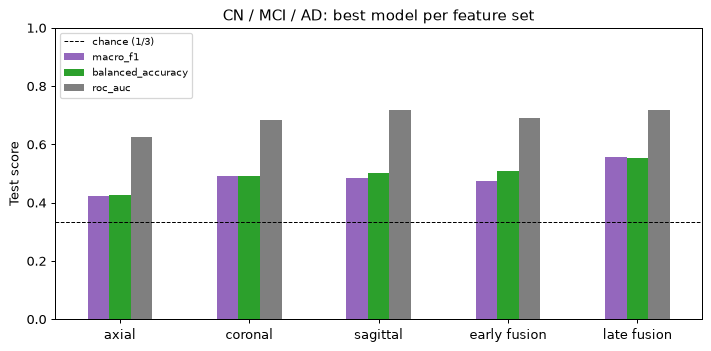

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
summary[["macro_f1", "balanced_accuracy", "roc_auc"]].plot.bar(ax=ax, rot=0, color=["tab:purple", "tab:green", "tab:gray"])
ax.axhline(1 / 3, color="k", linestyle="--", linewidth=0.8, label="chance (1/3)")
ax.set(ylim=(0, 1), ylabel="Test score", xlabel="", title="CN / MCI / AD: best model per feature set")
ax.legend(fontsize=8, loc="upper left")
fig.tight_layout()
save_figure(fig, "05_multiclass_summary")

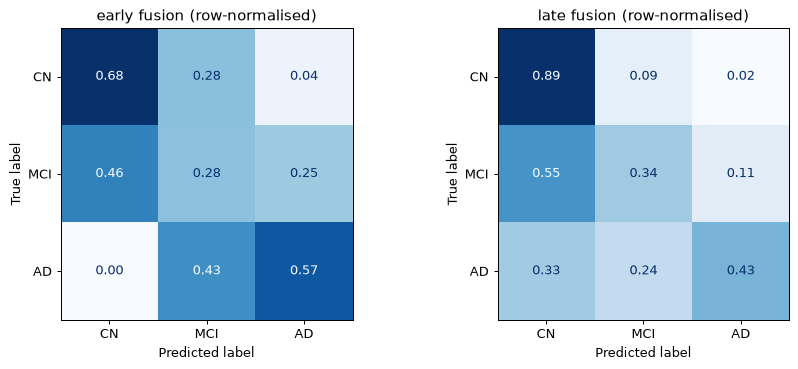

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, (title, pred) in zip(axes, [("early fusion", best_by_view["early fusion"]["model"].predict(X_test["early fusion"])), ("late fusion", pred_late)]):
    cm = confusion_matrix(yte, pred, labels=CLASSES, normalize="true")
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False, values_format=".2f")
    ax.set_title(f"{title} (row-normalised)")
fig.tight_layout()
save_figure(fig, "05_multiclass_confusion")

**Reading the confusion matrices.** Rows are the true class, normalised
to 1, so the diagonal is the per-class recall.

- **Late fusion is the best strategy** (macro-F1 0.56 vs 0.42–0.49 for single
  views; chance is 0.33). Early fusion (selected by CV: logistic regression,
  macro-F1 0.47) does not beat the best single view: concatenating ~260
  correlated features for ~870 subjects adds noise.
- **Errors follow the disease continuum with early fusion**: no AD subject is
  predicted as CN; misclassified AD subjects go to MCI. Late fusion leans
  towards CN (CN recall 0.89) at the cost of sending a third of AD subjects
  to CN.
- **MCI is the hardest class** (recall around 0.3), and is mostly confused with
  CN. This is expected: MCI is heterogeneous, and many MCI subjects have
  little cortical tau.